# Philadelphia Crime Incidents: Where and When to Be Careful


## 1. Load and clean the data

We keep the rows that have a usable location, pull the street name out of the address block, and tag each crime as either a **violent** offense (robbery, aggravated assault, weapons, sex offenses) or **property/other**. We also add a few time columns we'll need later (weekday, weekend flag).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
plt.rcParams["figure.dpi"] = 110

raw = pd.read_csv("data/incidents_part1_part2.csv")

df = raw.drop(columns=["gdb_geomattr_data"])
df = df.dropna(subset=["lat", "lng"])
df = df[(df["lat"].abs() > 1) & (df["lng"].abs() > 1)]

# pull street name out of the location_block string (e.g. "1200 BLOCK WALNUT ST")
has_block = df["location_block"].str.contains("BLOCK", na=False)
df["street"] = df["location_block"].str.split("BLOCK", n=1).str[-1].str.strip().str.upper()
df.loc[~has_block, "street"] = None

# tag each row as violent or property/other
VIOLENT_TYPES = [
    "Robbery No Firearm", "Robbery Firearm",
    "Aggravated Assault No Firearm", "Aggravated Assault Firearm",
    "Weapon Violations", "Other Sex Offenses (Not Commercialized)",
]
df["crime_group"] = np.where(df["text_general_code"].isin(VIOLENT_TYPES), "violent", "property/other")

# time helper columns
df["dispatch_date"] = pd.to_datetime(df["dispatch_date"])
df["month"] = df["dispatch_date"].dt.month
df["weekday"] = df["dispatch_date"].dt.day_name()
df["is_weekend"] = df["dispatch_date"].dt.dayofweek >= 5

print(f"{len(raw):,} rows loaded -> {len(df):,} rows after cleaning")
df[["dc_dist", "street", "text_general_code", "crime_group", "hour", "month", "weekday", "lat", "lng"]].head()

152,555 rows loaded -> 148,824 rows after cleaning


,dc_dist,street,text_general_code,crime_group,hour,month,weekday,lat,lng
0,1,JOHNSTON ST,Robbery No Firearm,violent,14,8,Friday,39.917257,-75.180239
1,12,ISLAND AVE,Theft from Vehicle,property/other,6,6,Sunday,39.912443,-75.242742
2,3,S 4TH ST,Robbery No Firearm,violent,23,5,Friday,39.934248,-75.150833
3,24,MEMPHIS ST,Robbery No Firearm,violent,20,12,Friday,39.985319,-75.113792
4,2,RISING SUN AVE,Thefts,property/other,14,8,Friday,40.050234,-75.094539


## 2. The ten questions



### Q1. How many event records are there in the dataset?

In [2]:
num_incidents = len(df)
print(f"There are {num_incidents:,} incidents in our dataset")


There are 148,824 incidents in our dataset


**Answer.** The cleaned dataset has **148,824** incidents for 2025. A small number of rows had no coordinates and were dropped during cleaning. (`dc_dist` is the police district number, e.g. 1, 9, 25.)

### Q2. What are the 10 most common types of crimes? (Visualization 1)

In [3]:
top_10_crimes = (
    df["text_general_code"]
    .value_counts()
    .head(10)
)

top_10_crimes


text_general_code
Thefts                            35709
Other Assaults                    26064
All Other Offenses                16205
Motor Vehicle Theft               14184
Vandalism/Criminal Mischief       12331
Theft from Vehicle                 9487
Fraud                              8795
Aggravated Assault No Firearm      5295
Burglary Residential               3001
Narcotic / Drug Law Violations     2445
Name: count, dtype: int64

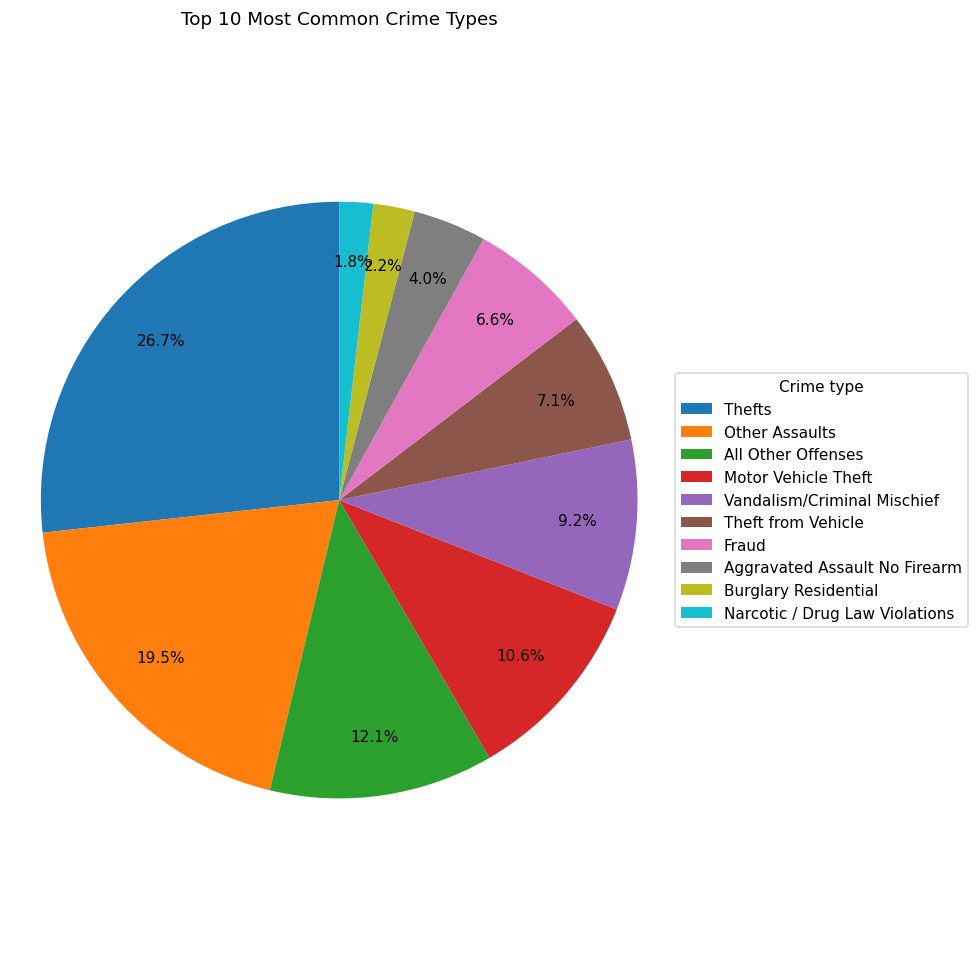

In [4]:
# keep it a pie chart, but move the long crime names into a legend on the right
# so the labels stop overlapping around the pie
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 9))
ax.pie(
    top_10_crimes,
    autopct="%1.1f%%",
    startangle=90,
    labels=None,          # no text around the pie -> no overlap
    pctdistance=0.8
)
ax.legend(
    top_10_crimes.index,
    title="Crime type",
    loc="center left",
    bbox_to_anchor=(1.0, 0.5)   # legend sits to the right, outside the pie
)
ax.set_title("Top 10 Most Common Crime Types")
ax.axis("equal")
plt.tight_layout()
plt.savefig("slides/q2_pie.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

**Answer.** Theft-related offenses dominate the top ten. The single most common is generic Thefts, and theft-from-vehicle / other thefts also sit near the top, so property crime outweighs violent crime in raw counts.

### Q3. Which hour of the day has the most events?

In [5]:
hourly_counts = df.groupby("hour").size()

peak_hour = hourly_counts.idxmax()
safest_hour = hourly_counts.idxmin()
print(f"Most events: {peak_hour}:00 ({hourly_counts[peak_hour]:,} incidents)")
print(f"Fewest events: {safest_hour}:00 ({hourly_counts[safest_hour]:,} incidents)")


Most events: 16:00 (11,071 incidents)
Fewest events: 6:00 (1,664 incidents)


**Answer.** Late afternoon, around 4–5 PM, is the busiest hour. The quietest hours are the early-morning window, so if you have flexibility, those hours carry the fewest incidents.

### Q4. What are the most common types of crimes during the day, evening, and late night, respectively?

In [6]:
def get_time_period(hour):
    if hour < 6:
        return "late night (0-6)"
    elif hour < 18:
        return "day (6-18)"
    else:
        return "evening (18-24)"

df["time_period"] = df["hour"].apply(get_time_period)

# top 3 crime types within each time period
for period, grp in df.groupby("time_period"):
    print(f"\n{period}  (n={len(grp):,})")
    print(grp["text_general_code"].value_counts().head(3))



day (6-18)  (n=96,591)
text_general_code
Thefts                 25520
Other Assaults         15844
Motor Vehicle Theft    10407
Name: count, dtype: int64

evening (18-24)  (n=36,594)
text_general_code
Thefts                8399
Other Assaults        7182
All Other Offenses    4766
Name: count, dtype: int64

late night (0-6)  (n=15,639)
text_general_code
Other Assaults        3038
All Other Offenses    2300
Thefts                1790
Name: count, dtype: int64


**Answer.** During the day the top crime is **Thefts** (25,520). In the evening Thefts stay high (8,399) but Other Assaults go up (7,182). Late at night the top crime is **Other Assaults** (3,038), so the mix shifts from property crime to assault/personal crime after dark.

### Q5. What are the most common crime types in different police districts?

In [7]:
dist_crime_num = df.groupby(["dc_dist", "text_general_code"]).size()
top_crime_dist = dist_crime_num.loc[dist_crime_num.groupby("dc_dist").idxmax()]
top_crime_dist


dc_dist  text_general_code 
1        Thefts                1145
2        Thefts                3156
3        Thefts                1810
5        Thefts                 614
7        Thefts                 907
8        Thefts                1841
9        Thefts                4758
12       Thefts                1690
14       Other Assaults        1830
15       Thefts                3130
16       Other Assaults        1005
17       Thefts                1570
18       Thefts                1686
19       Other Assaults        2360
22       Other Assaults        2359
24       All Other Offenses    2330
25       All Other Offenses    2623
26       Thefts                1361
35       Other Assaults        1596
39       Other Assaults        1440
77       Thefts                 422
dtype: int64

**Answer.** In most districts the most common crime is Thefts (For 13 districts).
Districts 14, 16, 19, 22, and 35 top out at Other Assaults, and districts 24 and 25 at All Other Offenses. The reason why thefts are the leading crime in most districts might be its easiness to commit with less risk of direct confrontation. Some other districts have different main crimes because their local conditions lead to more conflictions or minor offences.

### Q6. How does the number of incidents vary by month? (Visualization 2)

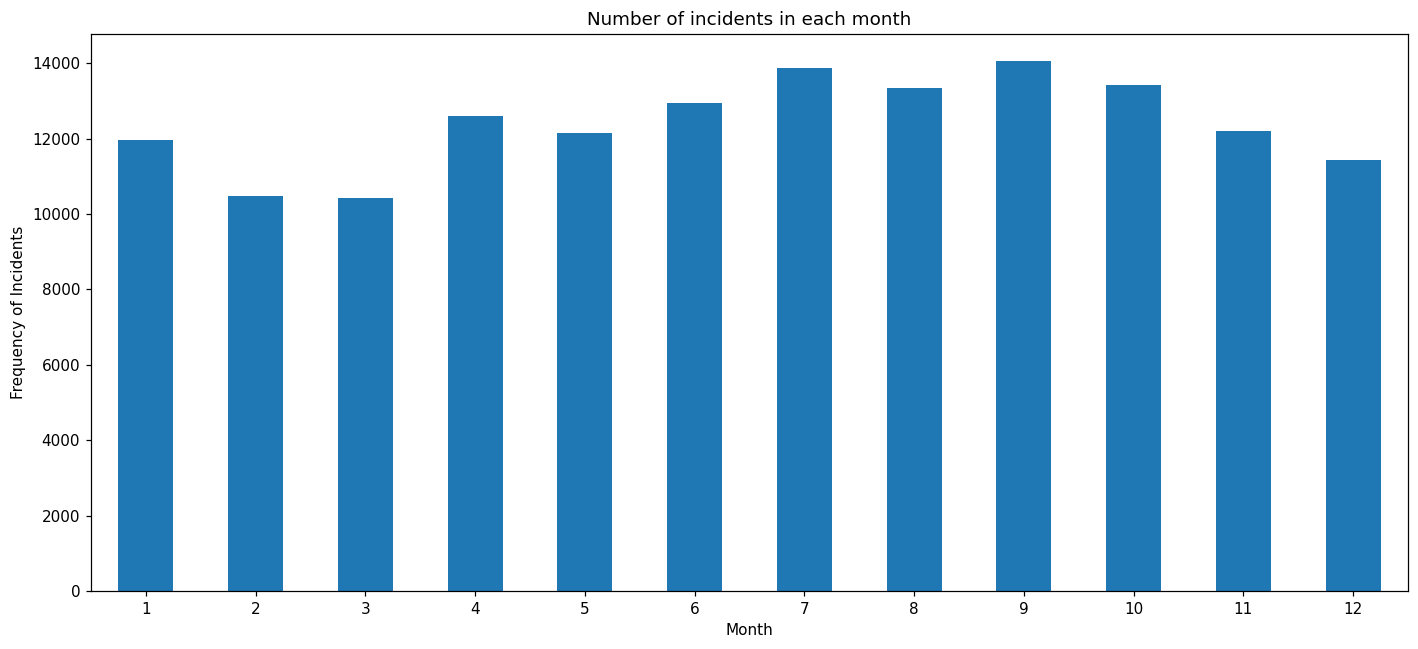

In [8]:
cnt_month = df["month"].value_counts().sort_index()
cnt_month.plot(kind="bar", title="Number of incidents in each month",
               xlabel="Month", ylabel="Frequency of Incidents", figsize=(13,6))
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("slides/q6_monthly.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()


**Answer.** Counts climb through spring, peak in the warmer months, and drop in winter. The most recent month may look low because the data cuts off mid-period, so treat the last bar as partial.

### Q7. Is there a seasonal pattern in crime incidents — for example, more in summer than in winter?

In [9]:
def dateToSeason(date):
    month = date.month
    if 3 <= month <= 5:
        return "spring"
    elif 6 <= month <= 8:
        return "summer"
    elif 9 <= month <= 11:
        return "fall"
    else:
        return "winter"

df["season"] = df["dispatch_date"].apply(dateToSeason)

# Total incident by season
print(df.groupby("season").size())

# daily average per season (so longer seasons aren't unfairly weighted)
daily_crime = (
    df.groupby(["season", "dispatch_date"])
      .size()
      .reset_index(name="crime_count")
)
season_daily_average = (
    daily_crime.groupby("season")["crime_count"]
               .mean()
               .sort_values(ascending=False)
)
season_daily_average


season
fall      39680
spring    35167
summer    40126
winter    33851
dtype: int64


season
summer    436.152174
fall      436.043956
spring    386.450549
winter    371.989011
Name: crime_count, dtype: float64

**Answer.** There is a seasonal lift but it is mild. Summer and fall are basically tied at the top, and winter sits only modestly lower - a gentle slope rather than a sharp summer spike.

### Q8. Which neighborhoods are consistently high-incidence locations rather than just occasional hotspots?

In [10]:
month_count = df.groupby(["location_block", "month"]).size().reset_index(name="num")

final_data = month_count.groupby("location_block").agg(
    avg_month=("num", "mean"),
    active=("month", "nunique")
).reset_index()

city_mean = final_data["avg_month"].mean()
city_std = final_data["avg_month"].std()
final_data["dev_from_avg"] = (final_data["avg_month"] - city_mean) / city_std

# a true long-term hotspot: shows up in many months AND far above the city average
final_result = final_data[(final_data["active"] >= 10) & (final_data["dev_from_avg"] > 10)]
final_result = final_result.sort_values(by="dev_from_avg", ascending=False)
final_result


,location_block,avg_month,active,dev_from_avg
23308,5500 BLOCK TULIP ST,45.500000,12,36.716882
10282,2100 BLOCK SOUTH ST,35.666667,12,28.546014
5348,1500 BLOCK SPRUCE ST,27.500000,12,21.760040
23582,5600 BLOCK VINE ST,24.500000,12,19.267233
24574,600 BLOCK FOULKROD ST,21.000000,12,16.358958
1528,1000 BLOCK MARKET ST,20.666667,12,16.081980
2070,1100 BLOCK CHESTNUT ST,20.583333,12,16.012735
5075,1500 BLOCK N 52ND ST,20.166667,12,15.666512
5578,1600 BLOCK CHESTNUT ST,19.083333,12,14.766332
5010,1500 BLOCK MARKET ST,18.666667,12,14.420108


**Answer.** A handful of blocks are stable, year-round hotspots - they appear in almost every month and sit many standard deviations above the city average. These are the locations to avoid consistently, not just on bad days.

### Q9. Has a particular type of crime increased or decreased over the past few months?

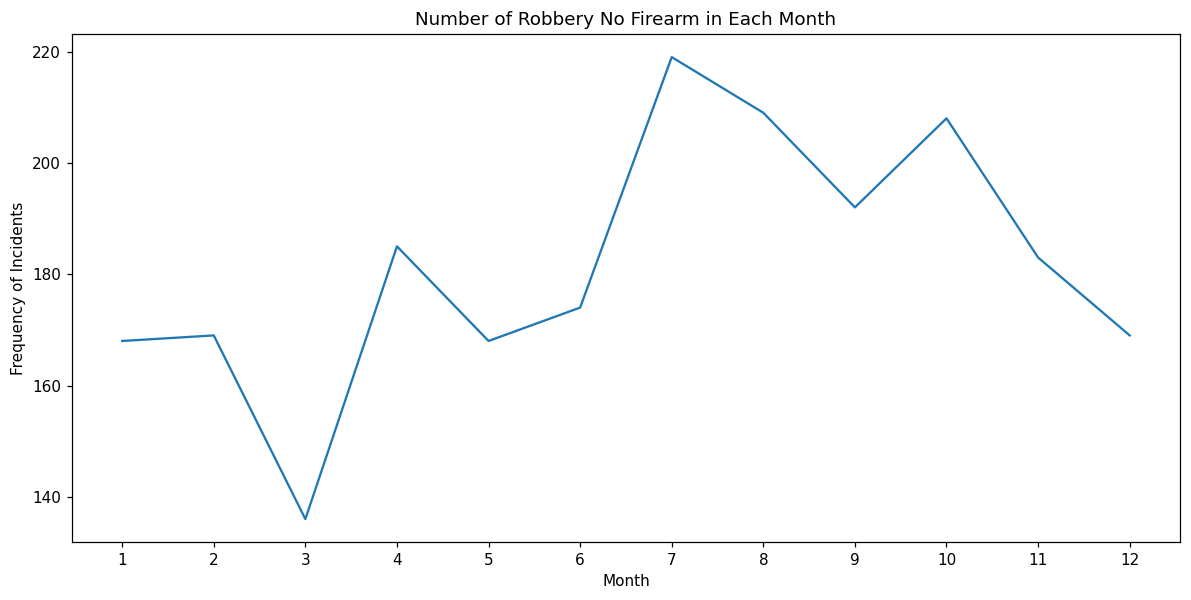

In [11]:
filtered_specific_crime = df[df["text_general_code"].str.contains("Robbery No Firearm", case=False, na=False)]
filtered_specific_crime = filtered_specific_crime["month"].value_counts().sort_index()
filtered_specific_crime.plot(kind="line", title="Number of Robbery No Firearm in Each Month",
                             xlabel="Month", ylabel="Frequency of Incidents", figsize=(13,6))
plt.xticks(ticks=range(1,13), labels=range(1,13))
plt.show()


**Answer.** Robbery No Firearm tracks the citywide seasonal shape - higher in the warmer months and lower in winter - rather than showing a steady upward or downward trend across the year.

### Q10. Which "police precinct × time period" combinations should students avoid most? (Visualization 3)

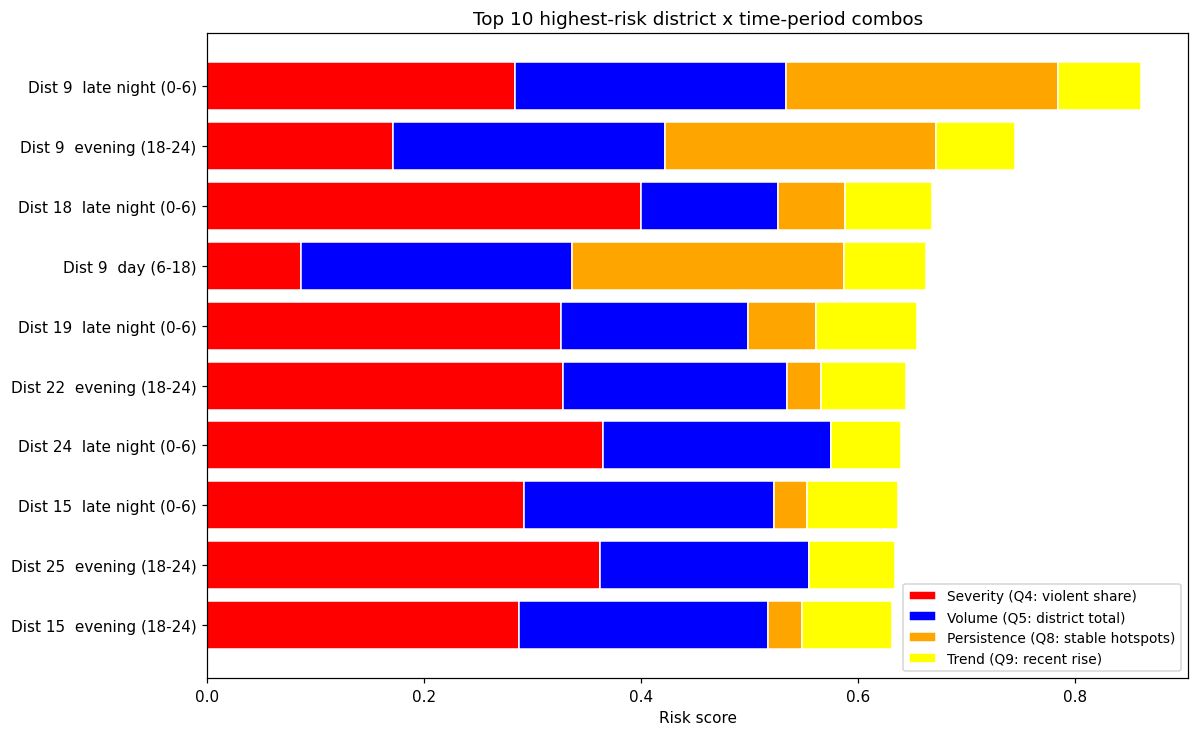

 dc_dist      time_period  severity  volume  persistence  trend  risk_score
       9 late night (0-6)     0.152   12924          8.0  0.184       0.861
       9  evening (18-24)     0.092   12924          8.0  0.173       0.744
      18 late night (0-6)     0.214    6492          2.0  0.190       0.668
       9       day (6-18)     0.046   12924          8.0  0.180       0.662
      19 late night (0-6)     0.174    8921          2.0  0.222       0.654
      22  evening (18-24)     0.175   10720          1.0  0.186       0.644
      24 late night (0-6)     0.195   10836          0.0  0.154       0.639
      15 late night (0-6)     0.156   11898          1.0  0.197       0.636
      25  evening (18-24)     0.193    9971          0.0  0.187       0.633
      15  evening (18-24)     0.153   11898          1.0  0.196       0.631


In [12]:
# Q10 - a composite risk score for each (district x time_period) cell.
# Four dimensions, each one reuses an earlier question's result.
# Scale each dimension by its own max, then add them up with weights.

# the grid we score: count of incidents in each (district, time_period) cell
cell = df.groupby(["dc_dist", "time_period"]).size().reset_index(name="total")
cell = cell[cell["total"] >= 50]   # skip tiny cells that are just noise

# DIM 1 - SEVERITY (from Q4: time_period + the "violent" crime_group tag)
# what share of the cell's incidents are violent crimes?
violent = df[df["crime_group"] == "violent"].groupby(["dc_dist", "time_period"]).size()
def get_severity(r):
    v = violent.get((r["dc_dist"], r["time_period"]), 0)
    return v / r["total"]

cell["severity"] = cell.apply(get_severity, axis=1)

# DIM 2 - VOLUME (from Q5: dist_crime_num, the per-district totals)
cell["volume"] = cell["dc_dist"].map(dist_crime_num.groupby("dc_dist").sum())

# DIM 3 - PERSISTENCE (from Q8: final_result, the stable-hotspot blocks)
# how many year-round hotspot blocks (Q8) fall inside this district?
hotspot_blocks = final_result["location_block"]
n_hot = df[df["location_block"].isin(hotspot_blocks)].groupby("dc_dist")["location_block"].nunique()
cell["persistence"] = cell["dc_dist"].map(n_hot).fillna(0)

# DIM 4 - TREND (from Q9: filtered_specific_crime, the Robbery monthly series)
# reuse Q9's idea: compare recent months to earlier months, per cell.
max_m = df["month"].max()
recent = df[df["month"] >= max_m - 1].groupby(["dc_dist", "time_period"]).size()
prior  = df[df["month"] <= max_m - 2].groupby(["dc_dist", "time_period"]).size()

def cell_trend(r):
    p = prior.get((r["dc_dist"], r["time_period"]), 0)
    if p == 0:
        return 1.0
    return recent.get((r["dc_dist"], r["time_period"]), 0) / p

cell["trend"] = cell.apply(cell_trend, axis=1)

# scale each dimension to 0-1 by dividing by its own max, then weight and add up
cell["sev_n"] = cell["severity"] / cell["severity"].max()
cell["vol_n"] = cell["volume"] / cell["volume"].max()
cell["per_n"] = cell["persistence"] / cell["persistence"].max()
cell["trd_n"] = cell["trend"] / cell["trend"].max()

# weighted sum - severity counts most, trend least (one year is a weak trend signal)
cell["risk_score"] = 0.4 * cell["sev_n"] + 0.25 * cell["vol_n"] + 0.25 * cell["per_n"] + 0.1 * cell["trd_n"]

top = cell.sort_values("risk_score", ascending=False).head(10)
top = top.iloc[::-1]   # reverse so the biggest bar is on top in the chart
labels = "Dist " + top["dc_dist"].astype(str) + "  " + top["time_period"].astype(str)

# stacked horizontal bar - one color per dimension, so you can see what drives each combo
fig, ax = plt.subplots(figsize=(11, 6.8))
left = [0] * len(top)
ax.barh(labels, 0.4  * top["sev_n"], left=left, color="red",    label="Severity (Q4: violent share)", edgecolor="white")
left = [l + v for l, v in zip(left, 0.4  * top["sev_n"])]
ax.barh(labels, 0.25 * top["vol_n"], left=left, color="blue",   label="Volume (Q5: district total)", edgecolor="white")
left = [l + v for l, v in zip(left, 0.25 * top["vol_n"])]
ax.barh(labels, 0.25 * top["per_n"], left=left, color="orange", label="Persistence (Q8: stable hotspots)", edgecolor="white")
left = [l + v for l, v in zip(left, 0.25 * top["per_n"])]
ax.barh(labels, 0.1  * top["trd_n"], left=left, color="yellow", label="Trend (Q9: recent rise)", edgecolor="white")

ax.set_xlabel("Risk score")
ax.set_title("Top 10 highest-risk district x time-period combos")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig("slides/q10_risk.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

print(top.iloc[::-1][["dc_dist", "time_period", "severity", "volume", "persistence", "trend", "risk_score"]]
      .round(3).to_string(index=False))

**Answer.** The highest-risk combos are a few districts in the evening and late-night windows. Each part of the score comes from an earlier question:

- **Time period**: from Q3 (busiest hour) and Q4 (late-night/evening have more violent share). That is why evening and late-night cells score high.
- **Volume**: from Q5 (per-district totals). Busier districts carry more baseline risk.
- **Persistence**: from Q8 (blocks that are hotspots year-round). A district with many of those blocks is risky on most days, not just once in a while.
- **Trend**: from Q9 (Robbery over time). It checks whether the risk is a long-term pattern.

Weights: severity 0.4, volume 0.25, persistence 0.25, trend 0.1. Severity counts most because it is closest to personal-safety risk. Trend counts least because one year of data gives only a weak trend signal.